# E85: Can VPD's adversary fail a bad placement on Qwen3-1.7B?

*2026-11-04, `qwen-decomp-lead`. Record: `reports/analyses/2026-11-04_analysis_e85-adversary-teeth.md`. Rules: `experiments/qwen_d1_teeth/results/predictions.json`.*

*For D1, a map on Qwen3-1.7B that keeps the decomposition faithful for a real update, judged by a test that can fail a bad placement.*

**Status: provisional. Independent check running.**

**The answer.** Not at the filed bars. We built two bad placements of Qwen's first update, and VPD's adversary failed neither at its filed final read. A random change in Δ read almost the same as the unchanged decomposition. Placing the update on rarely-on subcomponents read higher but under the pass bar. It sits right on the lower bar Qwen's own noise would give. Midway through the search that placement touched the fail bar, so the reading depends on where the search stops.


## What we were trying to test

D1 is a map on Qwen3-1.7B that keeps the decomposition faithful for a real update, judged by a test that can fail a bad placement. Earlier runs read VPD's adversary on doing nothing and on three placements of one update, and every one passed. No state built to be bad had been read, so nobody knew whether this adversary could fail anything on this model.

**The update.** W0 is Qwen3-1.7B before the update. The update δW, called u1, is ten steps of a fine-tune on maths problems.

**The adversary.** Each weight matrix is written as rank-one subcomponents plus a leftover Δ. Γ gives each subcomponent a causal importance $g$ from 0 to 1 on each token. The adversary picks a setting $s$ from 0 to 1 per subcomponent, shared by all rows and positions. It uses each subcomponent at strength $m = g + (1-g)s$, and it picks how much of Δ to keep per matrix. It takes 20 sign steps of 0.1 up the forward KL, KL[clean ‖ masked], from the state's own clean output to its masked output.

**The read.** A state's final KL over W0's final KL at the same seed, then the mean over two seeds. W0 reads 1 by definition. The filed bars are pass at 1.40 or under and fail at 1.61 or over, and they were carried over from the 67M model.

**The states, and what each rules out.**

- **W0**, the control, re-read first on this host at both seeds. If it moved, no ratio here would stand.
- **Random change in Δ.** W0 plus a Gaussian at u1's size per matrix, with subcomponents unmoved. Δ holds it and u1 is nowhere. It should fail if the adversary notices a change that carries none of the update.
- **Rarely-on placement.** Weights W0 plus u1, with the least-squares split of u1 over the half of alive subcomponents least often on moving those columns. The rest of u1 stays in Δ. It has the right total on the wrong columns, so it should fail if the adversary notices where an update sits.

An earlier run has two states under the name of the rarely-on half. Its clean table's row discards the remainder; this run uses the one that keeps the remainder in Δ. So its behaviour kept is 1.00 by construction and cannot read the placement.

**The reference.** Do-nothing, the whole update in Δ, was not re-read here: the run had six starts, as asked. Its 1.24 comes from an earlier run on another host of the same card model.


## What we expected, and why

We filed the outcome "the adversary cannot fail a bad state here" at medium confidence. The reasoning was that the Δ dial is the adversary's one clear lever on an update, so a state should read about what do-nothing reads. So random was expected near do-nothing's 1.24. The rarely-on placement was expected near 1.2 to 1.3, at low confidence. The doubt was that its moved columns carry over four times u1's input-weighted energy, and the adversary can raise exactly the columns whose importance is near 0. The filed rule for "cannot" also asks that no single seed reach the fail bar, because that outcome closes a line.


## What we observed

W0 re-read within its stops, and every build check passed.

### Does the adversary fail either bad state?


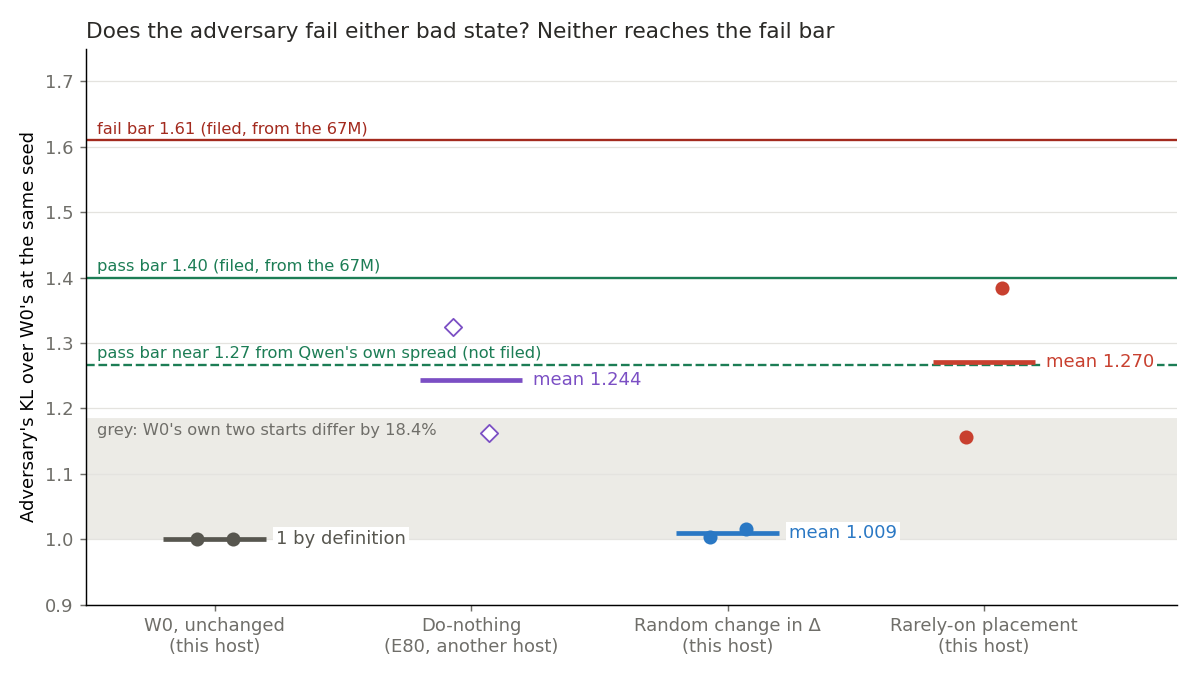

| state | seed 0 | seed 1 | mean | filed verdict |
|---|---|---|---|---|
| random change in Δ | 1.003 | 1.015 | 1.009 | pass |
| rarely-on placement | 1.157 | 1.384 | 1.270 | pass |

In [1]:
import json
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path("../experiments/qwen_d1_teeth")
RES, FIG = ROOT / "results", ROOT / "figures"
R = json.loads((RES / "results.json").read_text())
S = R["score"]

def show(name):
    display(Image(filename=str(FIG / name), width=760))

def table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

show("ratio_bars.png")
table(["state", "seed 0", "seed 1", "mean", "filed verdict"],
      [[name, f"{S['r'][k][0]:.3f}", f"{S['r'][k][1]:.3f}", f"{S['mean'][k]:.3f}", S["verdict"][k]] for name, k in (("random change in Δ", "Rand"), ("rarely-on placement", "Rare"))])


**Reading it.** No, not at the filed final read, so the filed outcome is "the adversary cannot fail a bad state here". The random change reads a mean of 1.009, and the rarely-on placement reads 1.270 with seeds of 1.157 and 1.384. Do-nothing's 1.24 is drawn from another host, and the rarely-on placement is not separated from it. The caveat is the bars themselves, which came from the 67M. The same formula on Qwen's own 18.4% spread gives a pass bar near 1.27 and a fail bar near 1.78. The rarely-on placement's 1.270 sits on that lower pass bar, so the reading is close there, and neither state nears either fail bar.


### Had the search finished, and does the ratio depend on when it is read?


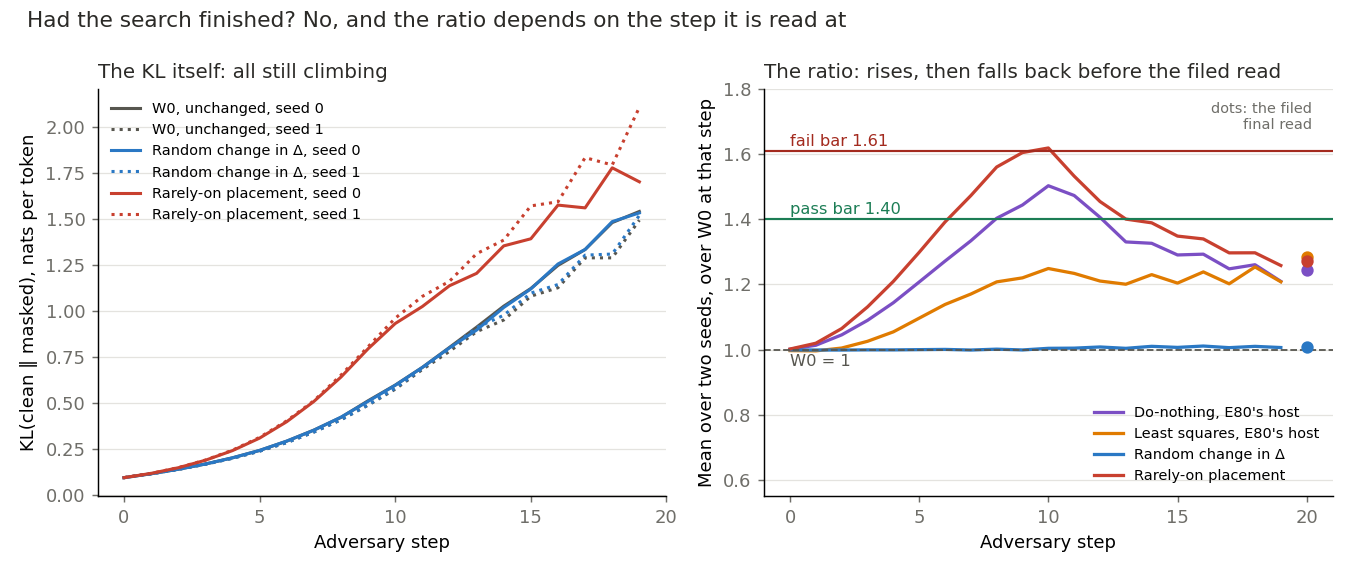

In [2]:
show("steps.png")


**Reading it.** The search had not finished, and yes, the ratio depends on the step. On the left the KL of every state is still climbing, so each final read is a lower bound. On the right the rarely-on placement's mean ratio rises to 1.62 at step 10, over the fail bar. It then falls back to 1.27 at the filed final read. Do-nothing does the same at a lower height, peaking near 1.50, and random stays flat at 1. The filed read is the final one and it stands. The rise and fall has no measured cause, and whether the ratio settles after 20 steps is not known.


### How bad are the two states by other checks?


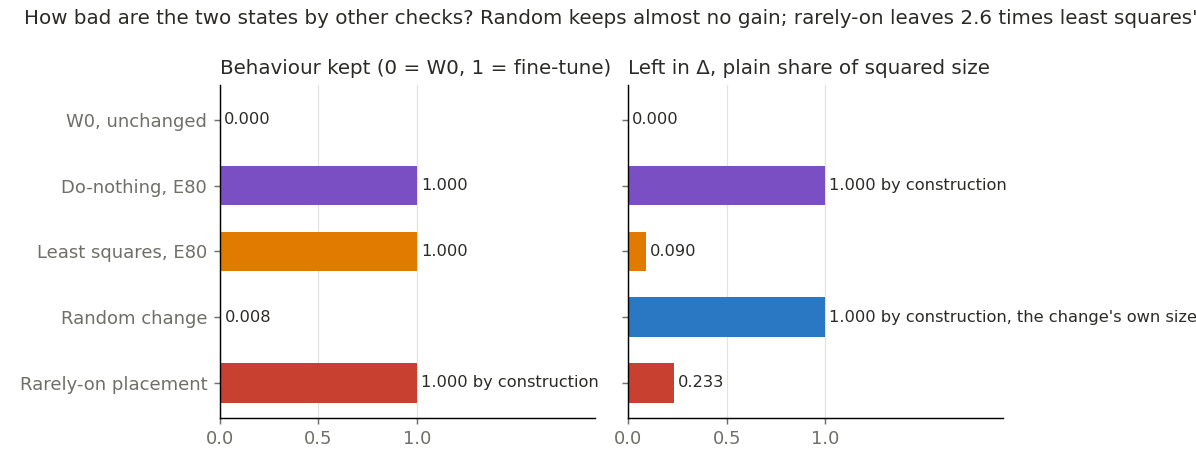

In [3]:
show("other_checks.png")


**Reading it.** Each is bad in a different way, and only the random change is bad on behaviour. Behaviour kept is the share of u1's loss drop on held-out maths problems, with no masks: 0 is W0 and 1 is the fine-tune. The random change keeps 0.008 and the rarely-on placement 1.00, which is by construction. Left in Δ is the plain share of u1's squared size outside the subcomponents. The rarely-on placement leaves 0.233 against least squares' 0.090, and the filed derivation had guessed about 0.35. For the random change the 1.00 is its own size, not u1's. So nothing here measures the rarely-on placement as bad on its columns: that is true by how it was built.


## What we learned

At the filed bars and final read, this adversary fails neither bad state on Qwen3-1.7B's first update. So it has not shown it can judge D1, a map on Qwen3-1.7B that keeps the decomposition faithful for a real update, by failing a bad placement. The adversary does read the two states differently, since random tracks W0 and the rarely-on placement sits above it on both seeds. That difference does not separate the rarely-on placement from doing nothing. For `GOALS.md`'s weak version, this says nothing about whether any placement is good.

**What this bears on, without deciding it.** The user has a pending question on what should judge that map, with three options:

- **A, the clean table, share left in Δ, size and kept on TOFU, with least squares as first map.** A already leaves the adversary out, and this result gives no reason to bring it back.
- **B, teacher training with masks in its loss as the map.** No teacher-trained state was read here, so it bears only on what could judge one.
- **C, that aim cannot be met as worded.** This read did not fail a right total on the wrong columns, the case C turns on.

## How compelling is the evidence

Moderate for the filed reading, weak beyond it. It is one update, two seeds per state, and web rows, on which u1 moves clean outputs little.

- **Controls.** W0's seed 0 reproduced the earlier run to every digit and seed 1 to 0.04%. Every build check passed.
- **Noise.** Two seeds differ by 0.012 for random and 0.227 for the rarely-on placement. So a mean of two carries about 0.1. Same-seed pairing is tight for random, within 3% of W0 at every step.
- **Blind to.** The ratio sees a placement only through the masks and the Δ dial, so a pass does not make a placement good. No state known to fail on this model has been read, so the test's power remains unshown.
- **Reference.** Do-nothing and least squares come from another host, though same-seed reads across those hosts agree closely.

## Surprises

**Something unexpected happened that I cannot explain.** We filed at medium confidence that the random change would read near do-nothing's 1.24. It read 1.009, below do-nothing and further from it than W0's spread. No cause is claimed.

- The rarely-on placement's mean ratio crossed the fail bar at one step of the twenty, under a read the rule does not use.
- Its share left in Δ read 0.233 against a derived 0.35, inside the stop's range.

## What next

- **The user's question on what judges the map.** It decides whether anything further runs on this adversary.
- **A proposal, not a plan: more than 20 steps on the rarely-on placement and do-nothing, on one host.** If the first settles over a bar and the second under it, the adversary may have teeth after all. If they settle together, the line closes on firmer ground.
- **A proposal: read the masks with Γ given unrounded V.** If the masks move on the moved columns, earlier readings of how masks respond need revisiting.


## Scorecard


In [4]:
l = S["leans"]
yes = lambda b: "held" if b else "missed"
table(["id", "claim", "rule", "read", "verdict"], [
    ["outcome", "neither bad state fails", "both means ≤ 1.40, no seed ≥ 1.61", f"{S['mean']['Rand']:.3f}, {S['mean']['Rare']:.3f}", S["outcome"]],
    ["W0_s0", "W0 re-reads, or stop", "1.363 to 2.044", f"{S['W0'][0]:.4f}", "held"],
    ["W0_s1", "W0 re-reads, or stop", "1.150 to 1.726", f"{S['W0'][1]:.4f}", "held"],
    ["Rand_passes", "random passes, medium lean", "≤ 1.40", f"{S['mean']['Rand']:.3f}", yes(l["Rand_passes"])],
    ["Rare_passes", "rarely-on passes, low lean", "≤ 1.40", f"{S['mean']['Rare']:.3f}", yes(l["Rare_passes"])],
    ["Rand_near_do_nothing", "random near do-nothing, medium lean", "gap to 1.2435 ≤ spread", f"gap 0.235, spread {S['W0_spread']:.3f}", yes(l["Rand_near_do_nothing"])],
    ["Rare_near_inspan", "rarely-on near in-span, low lean", "gap to 1.2784 ≤ spread", f"gap 0.008, spread {S['W0_spread']:.3f}", yes(l["Rare_near_inspan"])],
    ["Rand_kept_near_zero", "random keeps no gain, medium lean", "within 0.05 of 0", f"{S['kept']['Rand']:.4f}", yes(l["Rand_kept_near_zero"])],
    ["left_Rare", "rarely-on left in Δ, a stop", "between 0.090 and 1, about 0.35", f"{S['left_in_delta']['Rare']:.3f}", "in range"],
])


| id | claim | rule | read | verdict |
|---|---|---|---|---|
| outcome | neither bad state fails | both means ≤ 1.40, no seed ≥ 1.61 | 1.009, 1.270 | the adversary cannot fail a bad state here |
| W0_s0 | W0 re-reads, or stop | 1.363 to 2.044 | 1.7032 | held |
| W0_s1 | W0 re-reads, or stop | 1.150 to 1.726 | 1.4385 | held |
| Rand_passes | random passes, medium lean | ≤ 1.40 | 1.009 | held |
| Rare_passes | rarely-on passes, low lean | ≤ 1.40 | 1.270 | held |
| Rand_near_do_nothing | random near do-nothing, medium lean | gap to 1.2435 ≤ spread | gap 0.235, spread 0.184 | missed |
| Rare_near_inspan | rarely-on near in-span, low lean | gap to 1.2784 ≤ spread | gap 0.008, spread 0.184 | held |
| Rand_kept_near_zero | random keeps no gain, medium lean | within 0.05 of 0 | 0.0077 | held |
| left_Rare | rarely-on left in Δ, a stop | between 0.090 and 1, about 0.35 | 0.233 | in range |

## Departures from the literature

The adversary follows VPD's evaluation config: one source per subcomponent and one per matrix for Δ, shared by all rows. It takes 20 sign steps of 0.1 over 128 rows of 512 tokens.

- **A changed model.** VPD runs it on the model its decomposition was fitted to. Here Γ is frozen and reads weights it was not fitted to, because that is the question.
- **Ratio and bars.** VPD reports the KL alone. The ratio and both bars are this project's, carried from the 67M without a measurement on Qwen.
- **Starts.** We read two starts and the final step only, by the filed rule. The source does not address start-to-start noise.
- **Precision.** Components are fp32 and Γ is bf16. The authors' bf16 autocast cannot hold moved columns.
- **The states.** The rarely-on placement and the random change have no published source. The least-squares split is this project's.

## Not run

1. Do-nothing or least squares on this host.
2. A third start of any state.
3. More than 20 adversary steps, so the plateau is unknown.
4. What Γ reading V rounded to bf16 does to the masks: it matches the authors' code, and its effect is unmeasured.
5. The rarely-on half with its remainder discarded, under the adversary.
6. Maths rows, other updates, or any bar other than the filed ones as a rule.
7. Which subcomponents the adversary raises.

## Provenance

Results `experiments/qwen_d1_teeth/results/results.json` and `run.log`; figures from `plot.py`. One H200 NVL on Vast, 2.25 h of run in the log, peak GPU 66.4 GB. The plan estimated about $10.6; the bill is not in the repo. Independent check running.
